# Playground — ResNet (Guilherme)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_resnet_guilherme.ipynb)

**Playground que usa os módulos do repositório.** Dados, MFCC, normalização, SpecAugment na GPU, treino,
avaliação, latência e a varredura de configurações vêm de `dados/`, `treino/` e `avaliacao/`, as mesmas funções
do notebook principal e do playground da CNN 1D. Aqui você escreve **só o modelo** e as configurações que quer
testar.

Como usar:
1. Abra no Colab (Ambiente de execução → Alterar tipo → GPU). Para guardar as alterações:
   **Arquivo → Salvar uma cópia no GitHub** ou baixe o `.ipynb` e substitua este arquivo.
2. Implemente o modelo na seção **4. Modelo** (os pontos marcados com `TODO`). O decorador
   `@registrar_modelo` faz a classe do notebook **substituir** o arquivo de `modelos/` nesta sessão: o treino, a
   latência e a varredura passam a usá-la sem copiar nada.
3. Use `fracao < 1` nos hiperparâmetros para iterar rápido; para números de verdade, `fracao = 1.0` e 3 seeds.
4. Quando a arquitetura estiver definida, siga a seção **8. Levando para o repositório**.

O setup clona/atualiza o repositório: o que estiver no GitHub (branch `main`) é o que roda.

## 1. Setup

No Colab, o Google Drive é montado: o `.tar.gz` do GSC, o cache de MFCC e os treinos ficam em
`MyDrive/kws-borda/` e sobrevivem ao fim da sessão (são os mesmos do notebook principal).

In [10]:
#@title Setup — rode esta célula primeiro
#Funciona no Colab (clona o repo e usa o Drive) e localmente/VS Code (usa a pasta do repositório).
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/gpeuzinCosta/kws-borda.git"
NO_COLAB = "google.colab" in sys.modules

if NO_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    REPO = Path("/content/kws-borda")
    if REPO.exists():
        subprocess.run(["git", "-C", str(REPO), "pull", "-q"], check=True)     #pega a versão mais nova dos módulos
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO / "requirements.txt")], check=True)

    #Drive: cache de MFCC, runs e resultados PERSISTEM entre sessões
    #Disco local (/content/data): áudios extraídos, leitura rápida (o Drive é lento para 100 mil arquivos)
    os.environ["KWS_DRIVE"] = "/content/drive/MyDrive/kws-borda"
    os.environ["KWS_DATA"] = "/content/data"
else:
    #Local: sobe a partir da pasta atual até achar a raiz do repositório
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())

#A raiz do repo no sys.path deixa importar as pastas: configs, dados, modelos, treino, avaliacao
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import torch
from configs import pastas_projeto, escolher_device

PASTAS = pastas_projeto()
DOWNLOADS = Path(os.environ.get("KWS_DRIVE", REPO)) / "downloads"     #.tar.gz/.zip baixados UMA vez
device = escolher_device()
commit = subprocess.run(["git", "-C", str(REPO), "rev-parse", "--short", "HEAD"],
                        capture_output=True, text=True).stdout.strip()

print(f"Colab: {NO_COLAB} | device: {device} | commit do código: {commit}")
print(f"torch {torch.__version__} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else '—'}")
for nome, p in PASTAS.items():
    print(f"  {nome:10s} -> {p}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab: True | device: cuda | commit do código: d44898f
torch 2.14.1+cu130 | GPU: Tesla T4
  dados      -> /content/data
  cache      -> /content/drive/MyDrive/kws-borda/cache
  runs       -> /content/drive/MyDrive/kws-borda/runs
  resultados -> /content/drive/MyDrive/kws-borda/runs


## 2. Hiperparâmetros

Vêm de `configs/base.yaml` (regras comuns a todos) + `configs/<modelo>.yaml` (só o que muda). Aqui ficam só as
sobrescritas deste playground.

In [ ]:
from configs import carregar_config

NOME_MODELO = "resnet"

hyperparameters = carregar_config(NOME_MODELO,
                                  fracao=1,      #fração do TREINO (1.0 = tudo). Val e teste são sempre completos
                                  epocas=20,
                                  seeds=[0, 1, 2],       #[0, 1, 2] para os números de verdade
                                  pool=[3, 4],         #res8 (lista, não tupla: o config.yaml do run não aceita tupla)
                                  dilatacao=False,     
                                  conv_extra=False)    
hyperparameters

{'dataset': 'speech_commands_v2',
 'tarefa': 'gsc35',
 'sample_rate': 16000,
 'duracao_s': 1.0,
 'n_mfcc': 40,
 'janela_ms': 30,
 'passo_ms': 10,
 'center': True,
 'n_mels': 40,
 'f_min': 20,
 'f_max': 7600,
 'normalizacao': 'global',
 'spec_augment': True,
 'fracao': 0.2,
 'epocas': 20,
 'batch_size': 128,
 'learning_rate': 0.003,
 'weight_decay': 0.01,
 'otimizador': 'adamw',
 'scheduler': 'onecycle',
 'label_smoothing': 0.1,
 'seeds': [0],
 'num_workers': 0,
 'latencia_repeticoes': 300,
 'latencia_aquecimento': 30,
 'latencia_threads': 1,
 'snrs_db': [20, 10, 5, 0, -5],
 'margem_pp': 2.0,
 'modelo': 'resnet',
 'canais': 45,
 'n_blocos': 3,
 'pool': [3, 4],
 'dilatacao': False,
 'conv_extra': False,
 'n_classes': 35,
 'n_frames': 101}

## 3. Dados

O GSC v2 é baixado para o Drive **uma vez**, e o MFCC de treino/val/teste é calculado uma vez e guardado em
cache (`carregar_dados`). O `criar_dataloaders` normaliza com as estatísticas do treino e entrega o batch inteiro
com um fatiamento; o SpecAugment é aplicado depois, no batch, na GPU, dentro do treino.

In [12]:
import subprocess, sys
from dados import classes_da_tarefa, criar_dataloaders
from treino.varredura import carregar_dados

subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "gsc",
                "--destino", str(PASTAS["dados"]), "--arquivos", str(DOWNLOADS)], check=True)
RAIZ_GSC = PASTAS["dados"] / "gsc"
CLASSES = classes_da_tarefa(hyperparameters["tarefa"])

dados = carregar_dados(hyperparameters, RAIZ_GSC, PASTAS["cache"])
loaders, (media, desvio) = criar_dataloaders(hyperparameters, dados)

xb, yb = next(iter(loaders["treino"]))
print("batch:", tuple(xb.shape), "| treino:", len(loaders["treino"].dataset), "áudios")   #esperado: (128, n_mfcc, n_frames)

batch: (128, 40, 101) | treino: 16968 áudios


## 4. Modelo

**Contrato** (o mesmo da bancada):
- entrada `x`: `(B, n_mfcc, n_frames)`, o MFCC normalizado (40 × 101 no padrão, 10 × 49 no `hello_edge`;
  não fixe esses números no código);
- saída: logits `(B, n_classes)`;
- a última camada se chama `self.head`;
- o `__init__` recebe `n_classes, n_mfcc, n_frames` e, depois, os hiperparâmetros da arquitetura (que vêm do
  `configs/<modelo>.yaml` e das configurações da varredura).

A `ResNet` abaixo é o esqueleto: implemente as camadas e o `forward`. Os hiperparâmetros da arquitetura
(`canais`, `n_blocos`) vêm do `configs/resnet.yaml` e podem ser variados na varredura (seção 7).

In [13]:
import torch
from modelos import registrar_modelo


@registrar_modelo("resnet", familia="ResNet", referencia="He et al. 2016; Tang & Lin 2018 (res8)")
class ResNet(torch.nn.Module):

    def __init__(self, n_classes, n_mfcc=40, n_frames=101, canais=45, n_blocos=3,
                 pool=(3, 4), dilatacao=False, conv_extra=False):      #pool, dilatacao, conv_extra
        super().__init__()

        k = 3   #kernel 3x3 em todas as camadas, como no Tang & Lin

        #Entrada: 1 canal -> canais
        self.conv0 = torch.nn.Conv2d(1, canais, k, padding=1, bias=False) #o Batch norm vai anular qualquer bias, pois subtrai a media do batch
        self.bn0   = torch.nn.BatchNorm2d(canais)

        #NOVO: res8 usa pool 3x4, res26 usa 2x2 e res15 não usa pooling
        if pool is None:
            self.pool = torch.nn.Identity()
        else:
            self.pool = torch.nn.AvgPool2d(pool)

        #Blocos residuais: 2 convs por bloco (+1 conv extra no res15)
        n_convs = 2 * n_blocos                       
        if conv_extra:                              
            n_convs = n_convs + 1
        self.convs = torch.nn.ModuleList()           
        self.bns   = torch.nn.ModuleList()           
        for i in range(1, n_convs + 1):              
            if dilatacao:
                d = 2 ** (i // 3)                    #res15: 1,1,2,2,2,4,4,4,8,8,8,16,16
            else:
                d = 1
            #padding = d mantém o tamanho do mapa, para a soma com o atalho bater
            self.convs.append(torch.nn.Conv2d(canais, canais, k, padding=d, dilation=d, bias=False))
            self.bns.append(torch.nn.BatchNorm2d(canais))

        self.relu = torch.nn.ReLU()
        self.gap  = torch.nn.AdaptiveAvgPool2d((1, 1))
        self.head = torch.nn.Linear(canais, n_classes)    #última camada sempre com o nome `head`

    def forward(self, x):
        #x: (B, n_mfcc, n_frames) -> logits (B, n_classes)
        x = x.unsqueeze(1)      #(B, 1, n_mfcc, n_frames): 1 canal, como uma imagem em tons de cinza

        x = self.relu(self.bn0(self.conv0(x))) #primeira conv com norm e relu
        x = self.pool(x)

        #cada bloco = conv -> norm -> ReLu -> conv -> norm, soma o atalho, ReLu
        for b in range(len(self.convs) // 2):
            atalho = x
            y = self.relu(self.bns[2 * b](self.convs[2 * b](x)))
            y = self.bns[2 * b + 1](self.convs[2 * b + 1](y))
            x = self.relu(y + atalho)

        #conv extra do res15 (sobra 1 conv quando o total é ímpar)
        if len(self.convs) % 2 == 1:
            x = self.relu(self.bns[-1](self.convs[-1](x)))

        #Descarta posicoes e mantem so uma intensidade media para a fully connected ter menos parametros
        x = self.gap(x)                               # (B, canais, 1, 1)
        x = x.view(x.size(0), -1)                     # (B, canais)

        return self.head(x)                           # (B, n_classes) — logits crus

In [14]:
from modelos import criar_modelo
from avaliacao import custo

modelo = criar_modelo(NOME_MODELO, hyperparameters)
print("classe usada:", type(modelo).__name__, "| definida em:", type(modelo).__module__)   #'__main__' = a deste notebook

#Contrato
saida = modelo.eval()(xb)
print("entrada:", tuple(xb.shape), "| saída:", tuple(saida.shape))      #esperado: (128, 35)
assert saida.shape == (len(xb), len(CLASSES)), f"saída {tuple(saida.shape)}, esperado ({len(xb)}, {len(CLASSES)})"
assert hasattr(modelo, "head"), "a última camada deve se chamar `head`"

c = custo(modelo)
print(f"parâmetros: {c['params']:,} | {c['kb_int8']:.1f} KB int8 | MACs: {c['macs']:,}")

classe usada: ResNet | definida em: __main__
entrada: (128, 40, 101) | saída: (128, 35)
parâmetros: 111,995 | 109.4 KB int8 | MACs: 37,176,525


In [15]:
import pandas as pd

#As 6 famílias do Tang & Lin (2018): o que muda em relação ao hyperparameters
familias = {
    'res8':         {'canais': 45, 'n_blocos': 3,  'pool': [3, 4], 'dilatacao': False, 'conv_extra': False},   
    'res8-narrow':  {'canais': 19, 'n_blocos': 3,  'pool': [3, 4], 'dilatacao': False, 'conv_extra': False},   
    'res15':        {'canais': 45, 'n_blocos': 6,  'pool': None,   'dilatacao': True,  'conv_extra': True},
    'res15-narrow': {'canais': 19, 'n_blocos': 6,  'pool': None,   'dilatacao': True,  'conv_extra': True},
    'res26':        {'canais': 45, 'n_blocos': 12, 'pool': [2, 2], 'dilatacao': False, 'conv_extra': False},   
    'res26-narrow': {'canais': 19, 'n_blocos': 12, 'pool': [2, 2], 'dilatacao': False, 'conv_extra': False},   
}

#Valores da Tabela do paper, só como referência (eles usam 12 classes, nós 35)
paper = {'res8': (110_000, 30e6), 'res8-narrow': (19_900, 5.65e6),
         'res15': (238_000, 894e6), 'res15-narrow': (42_600, 160e6),
         'res26': (438_000, 380e6), 'res26-narrow': (78_400, 77.1e6)}

x_teste = xb[:8]    #só 8 exemplos: o res15 em CPU com batch 128 demora
linhas = []
for nome, mudancas in familias.items():
    hp = {**hyperparameters, **mudancas}      #o hyperparameters original não é alterado
    modelo = criar_modelo(NOME_MODELO, hp)

    #Contrato
    with torch.no_grad():
        saida = modelo.eval()(x_teste)
    assert saida.shape == (len(x_teste), len(CLASSES)), f"{nome}: saída {tuple(saida.shape)}"

    c = custo(modelo)
    linhas.append({'familia': nome,
                   'params': c['params'], 'params paper': paper[nome][0],
                   'MACs (M)': c['macs'] / 1e6, 'mult paper (M)': paper[nome][1] / 1e6,
                   'KB int8': c['kb_int8']})

display(pd.DataFrame(linhas).round(1))

,familia,params,params paper,MACs (M),mult paper (M),KB int8
0,res8,111995,110000,37.2,30.0,109.4
1,res8-narrow,20631,19900,7.0,5.6,20.1
2,res15,240200,238000,958.8,894.0,234.6
3,res15-narrow,43640,42600,171.3,160.0,42.6
4,res26,441665,438000,439.0,380.0,431.3
5,res26-narrow,79797,78400,78.7,77.1,77.9


## 5. Treino e avaliação de um baseline

O loop único da bancada (`treino/loop.py`): AdamW, OneCycle, entropia cruzada com label smoothing, SpecAugment
no batch e os pesos da melhor época na validação.

época  1/20 | perda treino: 3.4868 | perda val: 3.3274 | acurácia val: 11.51% | 6s
época  2/20 | perda treino: 3.1232 | perda val: 2.8722 | acurácia val: 29.18% | 4s
época  3/20 | perda treino: 2.5341 | perda val: 2.9814 | acurácia val: 25.96% | 4s
época  4/20 | perda treino: 1.9981 | perda val: 2.0649 | acurácia val: 52.30% | 4s
época  5/20 | perda treino: 1.7048 | perda val: 1.9475 | acurácia val: 57.57% | 4s
época  6/20 | perda treino: 1.5371 | perda val: 1.6754 | acurácia val: 64.94% | 4s
época  7/20 | perda treino: 1.4043 | perda val: 1.9165 | acurácia val: 59.09% | 4s
época  8/20 | perda treino: 1.3265 | perda val: 1.6199 | acurácia val: 70.39% | 4s
época  9/20 | perda treino: 1.2727 | perda val: 1.2909 | acurácia val: 82.63% | 4s
época 10/20 | perda treino: 1.2120 | perda val: 1.1830 | acurácia val: 86.54% | 4s
época 11/20 | perda treino: 1.1699 | perda val: 1.2413 | acurácia val: 84.48% | 4s
época 12/20 | perda treino: 1.1423 | perda val: 1.1788 | acurácia val: 86.20% | 4s
époc

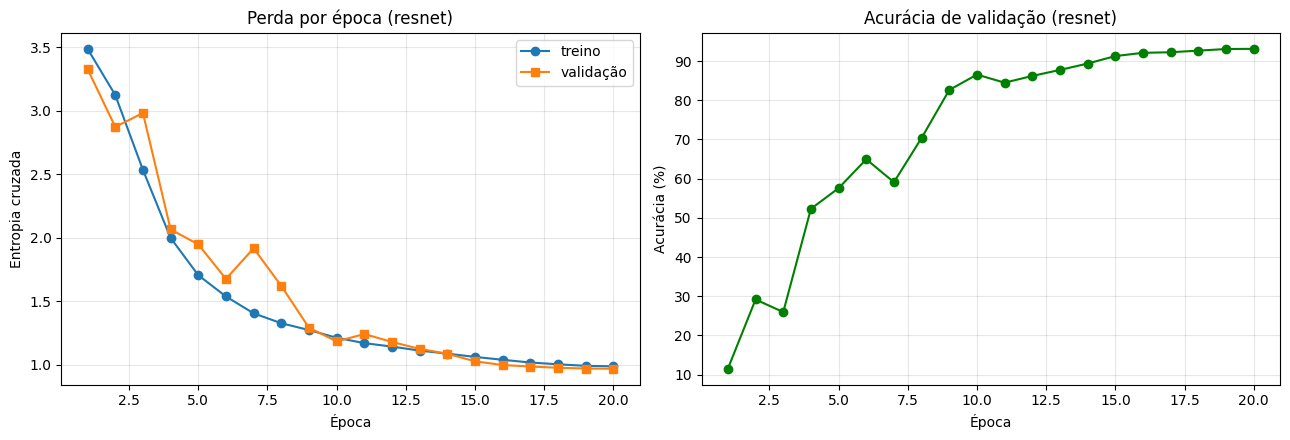

Gap (val - treino): -0.0190 | 1.4 min


In [ ]:
from treino import treinar
from avaliacao.graficos import curvas_treino

#mostra qual ResNet vai ser treinada
print(f'treinando: {NOME_MODELO} | canais: {hyperparameters["canais"]} | n_blocos: {hyperparameters["n_blocos"]} | '
      f'pool: {hyperparameters["pool"]} | dilatacao: {hyperparameters["dilatacao"]} | conv_extra: {hyperparameters["conv_extra"]}')

model_base, hist_base = treinar(criar_modelo(NOME_MODELO, hyperparameters), loaders, hyperparameters,
                                seed=hyperparameters["seeds"][0], device=device)
curvas_treino(hist_base, titulo=f"({NOME_MODELO} — res8 baseline)")      # título diz qual família
print(f'Gap (val - treino): {hist_base["gap"]:+.4f} | {hist_base["tempo_min"]:.1f} min')

teste | acurácia: 91.48% | F1 macro: 0.9072


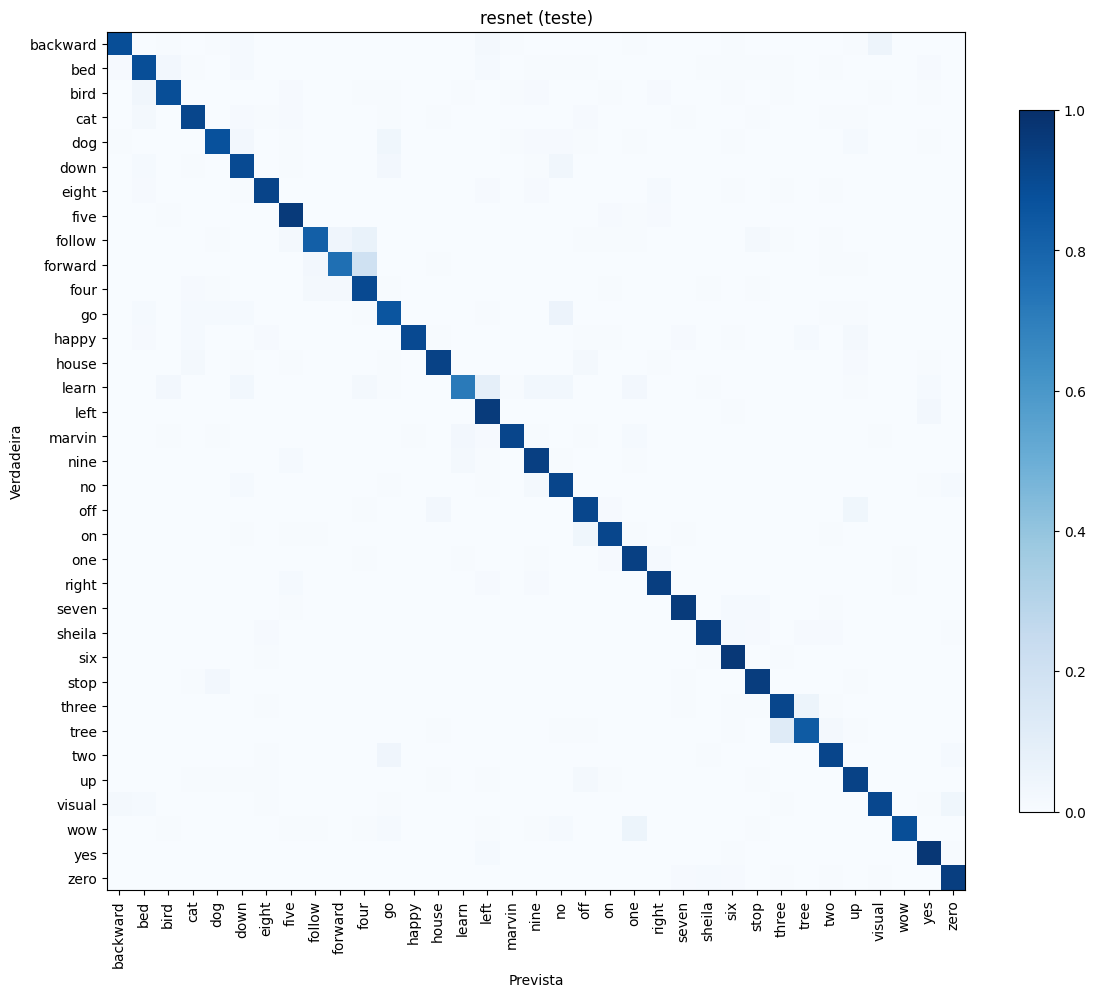

,verdadeira,prevista,fração
0,forward,four,0.200000
1,tree,three,0.119171
2,learn,left,0.086957
3,follow,four,0.069767
4,go,no,0.054726
5,three,tree,0.054321
6,wow,one,0.053398
7,backward,visual,0.048485
8,follow,forward,0.040698
9,two,go,0.040094


,precisao,revocacao,f1,exemplos
forward,0.891,0.836,0.862,146
learn,0.870,0.891,0.880,128
go,0.920,0.868,0.893,372
tree,0.914,0.874,0.894,159
up,0.865,0.931,0.897,350
follow,0.950,0.856,0.900,132
off,0.903,0.901,0.902,373
bed,0.891,0.920,0.905,213
bird,0.921,0.896,0.908,182
dog,0.905,0.914,0.909,197


In [17]:
import pandas as pd
from treino import prever
from avaliacao import acuracia, f1_macro, matriz_confusao, top_confusoes, relatorio_por_classe
from avaliacao.graficos import plot_matriz_confusao

y_pred, y_true = prever(model_base, loaders["teste"])
print(f"teste | acurácia: {acuracia(y_pred, y_true)*100:.2f}% | F1 macro: {f1_macro(y_pred, y_true):.4f}")

cm = matriz_confusao(y_pred, y_true, len(CLASSES))
plot_matriz_confusao(cm, CLASSES, titulo=f"{NOME_MODELO} (teste)")
display(pd.DataFrame(top_confusoes(cm, CLASSES, k=10), columns=["verdadeira", "prevista", "fração"]))

#Ranking de F1 por classe na VALIDAÇÃO (do pior para o melhor)
y_pred_val, y_true_val = prever(model_base, loaders["val"])
display(relatorio_por_classe(y_pred_val, y_true_val, CLASSES).round(3))

## 6. Latência (MFCC × rede)

Protocolo da hipótese (b): CPU com **1 thread**, **batch 1**, aquecimento e mediana; MFCC, normalização e rede
medidos separados, em rodadas, com aviso se a medida oscilar.

In [18]:
from avaliacao import medir_latencia

lat = medir_latencia(model_base, hyperparameters, media, desvio)
print(f"CPU: {lat['cpu']}")
print(f"MFCC: {lat['mfcc_ms']:.3f} ms | normalização: {lat['norm_ms']:.3f} ms | rede: {lat['rede_ms']:.3f} ms")
print(f"pré-processamento / rede = {lat['preproc_sobre_rede']:.2f}x | estável: {lat['estavel']}")

CPU: Intel(R) Xeon(R) CPU @ 2.00GHz
MFCC: 0.693 ms | normalização: 0.007 ms | rede: 2.943 ms
pré-processamento / rede = 0.24x | estável: True


## 7. Varredura: quanto dá para encolher?

Cada configuração é `(nome, o que muda em relação ao hyperparameters)`. A primeira se chama `baseline`: é a
referência do critério do projeto (o **menor** modelo até 2 p.p. abaixo dela na **validação**).
Com `retreinar=False`, o que já foi treinado (pesos no Drive, tabela `runs/varredura_<modelo>.csv`) é carregado.

In [ ]:
from treino.varredura import (rodar_varredura, medir_latencias_varredura, anexar_latencias, montar_resumo,
                              tabela_slide, escolher_vencedor, matrizes_escolhidos)


#mesmo desenho da varredura da CNN 1D (ablações só no baseline + encolher o modelo, com as duas entradas)
configs_varredura = [('baseline', {})]      #= res8 40x101: a referência, sempre a primeira

#Ablações de treino, só no baseline (as mesmas da CNN 1D, para comparar entre famílias)
configs_varredura.append(('sem spec_augment',  {'spec_augment': False}))
configs_varredura.append(('norm por_amostra',  {'normalizacao': 'por_amostra'}))
configs_varredura.append(('sem weight_decay',  {'weight_decay': 0.0}))

#Candidatos a "menor modelo": tudo que tem MENOS parâmetros que o res8 (+ o próprio res8, para o hello_edge)
candidatos = {
    'res8':           familias['res8'],
    'res8-narrow':    familias['res8-narrow'],
    'res15-narrow':   familias['res15-narrow'],
    'res26-narrow':   familias['res26-narrow'],
    'res8 canais 12': {**familias['res8'], 'canais': 12},     #achar onde a acurácia desaba
    'res8 canais 8':  {**familias['res8'], 'canais': 8},
}

entradas = {
    '':            {},
    'hello_edge':  {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False},
}

#Entrada por fora e modelo por dentro: o MFCC só troca uma vez
for nome_entrada, mudancas_entrada in entradas.items():
    for nome_candidato, mudancas_candidato in candidatos.items():
        if nome_entrada == '':
            nome = nome_candidato
        else:
            nome = f'{nome_candidato} + {nome_entrada}'

        if nome == 'res8':
            continue        #o res8 com a entrada padrão já é o baseline

        configs_varredura.append((nome, {**mudancas_candidato, **mudancas_entrada}))

for nome, mudancas in configs_varredura:
    print(nome)

SEEDS = hyperparameters["seeds"]
tabela, modelos = rodar_varredura(NOME_MODELO, configs_varredura, hyperparameters, SEEDS, RAIZ_GSC, PASTAS,
                                  retreinar=False, device=device)

baseline
res8-narrow
res15
res15-narrow
res26
res26-narrow
res8 + sem spec_augment
res8-narrow + sem spec_augment
res15 + sem spec_augment
res15-narrow + sem spec_augment
res26 + sem spec_augment
res26-narrow + sem spec_augment
res8 + hello_edge
res8-narrow + hello_edge
res15 + hello_edge
res15-narrow + hello_edge
res26 + hello_edge
res26-narrow + hello_edge


In [20]:
from avaliacao.graficos import acuracia_vs_custo_varredura, barras_preproc_rede

latencias = medir_latencias_varredura(NOME_MODELO, configs_varredura, hyperparameters)
tabela = anexar_latencias(tabela, latencias)
resumo = montar_resumo(tabela, hyperparameters["fracao"], hyperparameters["margem_pp"])

display(tabela_slide(resumo))
acuracia_vs_custo_varredura(resumo, hyperparameters["margem_pp"])
barras_preproc_rede(resumo)

KeyboardInterrupt: 

In [ ]:
vencedor = escolher_vencedor(resumo)

#Matrizes de confusão (no TESTE, somadas entre as seeds): baseline, vencedor e o que ficou logo abaixo da linha
matrizes_escolhidos(resumo, modelos, configs_varredura, hyperparameters, SEEDS, RAIZ_GSC, PASTAS["cache"])

## 8. Levando para o repositório

Quando a arquitetura estiver definida (o mesmo caminho da CNN 1D):
1. Copie a classe para `modelos/resnet.py`, no lugar do esqueleto, e mude `IMPLEMENTADO = True`.
2. Ponha a configuração vencedora em `configs/resnet.yaml` (seção `modelo:` e, se a entrada mudar, a seção
   `dados:` com o MFCC, como no `configs/cnn1d.yaml`).
3. Copie a lista `configs_varredura` para `treino/varredura.py` como `CONFIGS_RESNET`, com o MFCC e a arquitetura
   do baseline explícitos em cada linha (o YAML passa a guardar o vencedor, não o baseline).
4. Rode `pytest` para conferir o contrato.
5. No notebook principal, acrescente o estudo da ResNet no formato da §6.1 (CNN 1D).

